# Análisis Geoespacial IPM - Barrio Obrero (Versión 1 - área reducida)

Este notebook replica el análisis de Barrio Obrero pero recortando la información al **polígono V1** (`poligono_Barrio_Obrero_V1.geojson`), una versión más pequeña del barrio.

### Contexto y Cifras Generales (Corte Mayo 2026)

Para la interpretación de los resultados, se deben considerar dos lógicas opuestas:
1. **Índice de Condición Social (ICS):** Es un indicador directo; un valor del **100% representa el escenario óptimo** (bienestar y acceso pleno).
2. **Índice de Pobreza Multidimensional (IPM):** Es un indicador inverso; un valor del **100% representa el escenario crítico** (pobreza absoluta).

A nivel distrital, Cali presenta una marcada brecha territorial. La **severidad de la pobreza (IPM promedio en manzanas con incidencia > 0)** es del **15.28% en el área urbana**, mientras que en el **área rural se dispara al 38.33%**, impulsada principalmente por carencias en infraestructura básica en los corregimientos.

Este análisis se enfoca en el **polígono V1 (reducido)** de Barrio Obrero para identificar las privaciones específicas de esa área.

In [1]:
# 1. Instalación de dependencias (solo en Colab)
import sys
if 'google.colab' in sys.modules:
    !pip install geopandas matplotlib seaborn openpyxl -q

In [2]:
# 2. Importar librerías
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
import matplotlib.colors as mcolors
from matplotlib.patheffects import withStroke
import matplotlib.patches as mpatches

sns.set_style('white')
print('Librerías listas')

Librerías listas


In [3]:
# 3. Definir rutas con detección de entorno
REPO_URL = 'https://github.com/j0rg3c45/Pobreza_multidimensional_y_condicion_social.git'
REPO_DIR = 'Pobreza_multidimensional_y_condicion_social'

if 'google.colab' in sys.modules:
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL}
    else:
        !cd {REPO_DIR} && git pull
    BASE_DIR = REPO_DIR
else:
    if os.path.exists('indice_Pobreza'): BASE_DIR = '.'
    elif os.path.exists('../indice_Pobreza'): BASE_DIR = '..'
    elif os.path.exists('../../indice_Pobreza'): BASE_DIR = '../..'
    else: BASE_DIR = '.'

DATA_BASE = os.path.join(BASE_DIR, 'indice_Pobreza/data')

# Capas (el area de estudio es el poligono V1 - version reducida)
PATH_IPM_VARS_FULL = os.path.join(DATA_BASE, 'geojson_ipm/Mzn_ipm_variables.geojson')
PATH_ICS_FULL = os.path.join(DATA_BASE, 'geojosn_ICS/ics_mzn.geojson')
PATH_MANZANAS_FONDO = os.path.join(DATA_BASE, 'geojson_Manzanas_catastrales/geojson_Manzanas_catastrales.geojson')
PATH_AREA_ESTUDIO = os.path.join(DATA_BASE, 'geojson_poligonos_territorio_ITT/poligono_Barrio_Obrero_V1.geojson')

# Cargar datos
gdf_full = gpd.read_file(PATH_IPM_VARS_FULL)
gdf_ics_full = gpd.read_file(PATH_ICS_FULL)
gdf_fondo = gpd.read_file(PATH_MANZANAS_FONDO)
gdf_area = gpd.read_file(PATH_AREA_ESTUDIO)

# Unificar CRS a WGS84 (el poligono V1 viene en ESRI:103599)
gdf_full = gdf_full.to_crs('EPSG:4326')
gdf_ics_full = gdf_ics_full.to_crs('EPSG:4326')
gdf_fondo = gdf_fondo.to_crs('EPSG:4326')
gdf_area = gdf_area.to_crs('EPSG:4326')

# Filtrado espacial preciso (centroide dentro del poligono V1)
area_p = gdf_area.to_crs('EPSG:3115')
gdf_p = gdf_full.to_crs('EPSG:3115')
idx = gpd.sjoin(gdf_p.copy().assign(geometry=gdf_p.centroid), area_p[['geometry']], how='inner', predicate='within').index
gdf = gdf_full.loc[idx].copy()

# ICS para las mismas manzanas de la zona
ics_p = gdf_ics_full.to_crs('EPSG:3115')
idx_ics = gpd.sjoin(ics_p.copy().assign(geometry=ics_p.centroid), area_p[['geometry']], how='inner', predicate='within').index
gdf_ics = gdf_ics_full.loc[idx_ics].copy()

print(f'Manzanas IPM detectadas en Barrio Obrero V1: {len(gdf)}')
print(f'Manzanas ICS detectadas en Barrio Obrero V1: {len(gdf_ics)}')

Manzanas IPM detectadas en Barrio Obrero V1: 16
Manzanas ICS detectadas en Barrio Obrero V1: 16


Las 5 variables con mayor incidencia en Barrio Obrero V1 son:
- Informalidad (INFOR_): 84.66%
- Bajo Logro Educativo (BAJO_): 49.96%
- Dependencia Económica (DEPEN_): 21.79%
- Rezago Escolar (REZAGO_): 17.84%
- Sin Aseguramiento Salud (ASEGU_): 12.06%


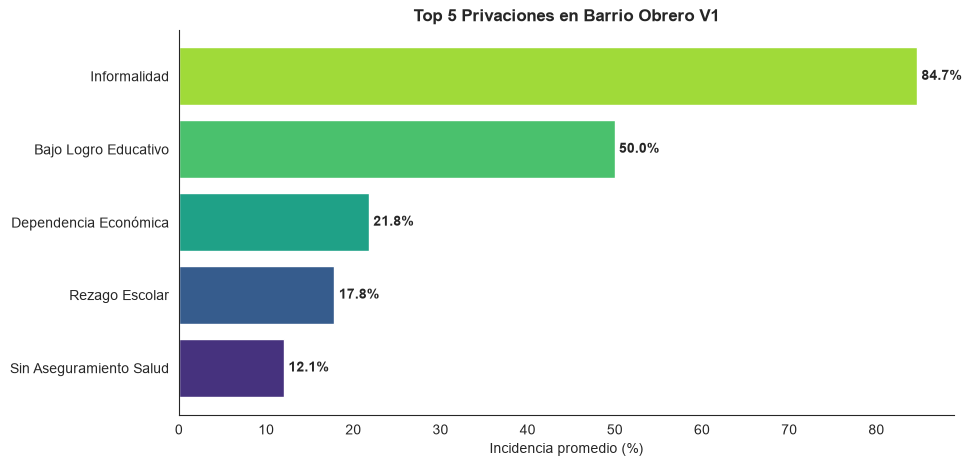

In [4]:
# 4. Escalas Maestras Notebook 01 (Comparabilidad Distrital)
RANGOS_IPM_8 = [
    (0.4, 20.0, "0.4% - 20.0%"),
    (20.1, 27.0, "20.1% - 27.0%"),
    (27.1, 33.1, "27.1% - 33.1%"),
    (33.2, 39.8, "33.2% - 39.8%"),
    (39.9, 48.6, "39.9% - 48.6%"),
    (48.7, 60.6, "48.7% - 60.6%"),
    (60.7, 80.0, "60.7% - 80.0%"),
    (80.1, 100.0, "80.1% - 100.0%")
]
cmap_master = plt.get_cmap("viridis", 8)
COLORES_IPM_8 = [mcolors.to_hex(cmap_master(i)) for i in range(8)]
CATEGORIAS_IPM_8 = ["Bajo", "Moderado-Bajo", "Moderado", "Moderado-Alto", "Alto", "Muy Alto", "Extremo", "Extremo Maximo"]

def _clasificar_ipm_master(gdf_zone, columna):
    datos = gdf_zone[columna].astype(float)
    cortes = [r[0] for r in RANGOS_IPM_8] + [RANGOS_IPM_8[-1][1]]
    etiquetas = [r[2] for r in RANGOS_IPM_8]
    res = gdf_zone.copy()
    res["_rango"] = pd.cut(datos, bins=cortes, labels=etiquetas, include_lowest=True, duplicates="drop")
    col_map = dict(zip(etiquetas, COLORES_IPM_8))
    res["_color"] = res["_rango"].astype(str).map(col_map).fillna("#BDBDBD")
    return res

variables_ipm = [
    'ANALF_', 'BAJO_', 'INFANCIA_', 'INASIS_', 'REZAGO_',
    'TRAB_INFAN', 'DEPEN_', 'INFOR_', 'SALUD_', 'ASEGU_',
    'HACI_', 'PARED_', 'EXCRE_', 'PISOS_', 'AGUA_'
]
diccionario_nombres = {
    'ANALF_': 'Analfabetismo', 'BAJO_': 'Bajo Logro Educativo', 'INFANCIA_': 'Barreras Infancia',
    'INASIS_': 'Inasistencia Escolar', 'REZAGO_': 'Rezago Escolar', 'TRAB_INFAN': 'Trabajo Infantil',
    'DEPEN_': 'Dependencia Económica', 'INFOR_': 'Informalidad', 'SALUD_': 'Barreras Salud',
    'ASEGU_': 'Sin Aseguramiento Salud', 'HACI_': 'Hacinamiento Crítico', 'PARED_': 'Paredes Inadecuadas',
    'EXCRE_': 'Excretas Inadecuadas', 'PISOS_': 'Pisos Inadecuados', 'AGUA_': 'Sin Agua Mejorada'
}
top_5 = gdf[variables_ipm].mean().sort_values(ascending=False).head(5).index.tolist()
print('Las 5 variables con mayor incidencia en Barrio Obrero V1 son:')
for v in top_5:
    print(f'- {diccionario_nombres[v]} ({v}): {gdf[v].mean():.2f}%')

top_means = gdf[top_5].mean().sort_values(ascending=True)
plt.figure(figsize=(10, 5))
plt.barh([diccionario_nombres[c] for c in top_means.index], top_means.values, color=cmap_master(np.linspace(0.2, 0.8, 5)))
for i, v in enumerate(top_means.values):
    plt.text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold')
plt.title("Top 5 Privaciones en Barrio Obrero V1", fontweight='bold')
plt.xlabel("Incidencia promedio (%)")
sns.despine()
plt.show()

In [5]:
# 5. Motor de Mapeo Maestro (Sincronización Total Colab 1)
def plot_ipm_variable_master(gdf_zone, gdf_back, gdf_poly, column, title):
    fig, ax = plt.subplots(1, 1, figsize=(18, 12))
    gdf_back.plot(ax=ax, color="#F8F8F8", edgecolor="#DCDCDC", linewidth=0.1, alpha=0.8, zorder=1)
    gdf_cl = _clasificar_ipm_master(gdf_zone, column)
    gdf_cl.plot(ax=ax, color=gdf_cl["_color"], edgecolor="white", linewidth=0.35, zorder=3, alpha=0.9)
    gdf_poly.boundary.plot(ax=ax, color="#D55E00", linewidth=1.5, linestyle="-", alpha=0.8, zorder=2)
    for _, fila in gdf_cl.iterrows():
        if pd.isna(fila[column]): continue
        punto = fila.geometry.representative_point()
        valor = float(fila[column])
        txt_color = "white" if valor > 0 else "black"
        stk_color = "black" if valor > 0 else "white"
        ax.text(punto.x, punto.y, f"{valor:.1f}", fontsize=7, ha="center", va="center", fontweight="bold",
                color=txt_color, path_effects=[withStroke(linewidth=1.5, foreground=stk_color, alpha=0.8)], zorder=5)
    minx, miny, maxx, maxy = gdf_cl.total_bounds
    rx, ry = maxx - minx, maxy - miny
    ax.set_xlim(minx - rx*0.15, maxx + rx*0.75)
    ax.set_ylim(miny - ry*0.15, maxy + ry*0.15)
    handles = [mpatches.Patch(facecolor=COLORES_IPM_8[i], edgecolor="white", label=f"{RANGOS_IPM_8[i][2]} | {CATEGORIAS_IPM_8[i]}") for i in range(8)]
    handles.append(mpatches.Patch(facecolor="none", edgecolor="#D55E00", linewidth=1.5, label="Area de estudio (V1)"))
    ax.legend(handles=handles, title=f"Privación: {title.upper()}\nRango % | Categoría",
              loc="center right", frameon=True, framealpha=0.9, fontsize=9, title_fontsize=11)
    ax.set_title(f"IPM por manzana: {title.upper()} - Barrio Obrero V1", fontsize=16, fontweight="bold", pad=20)
    ax.set_axis_off()
    plt.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.01)
    plt.show()

Generando mapas sincronizados con el Estándar Maestro del Notebook 01...


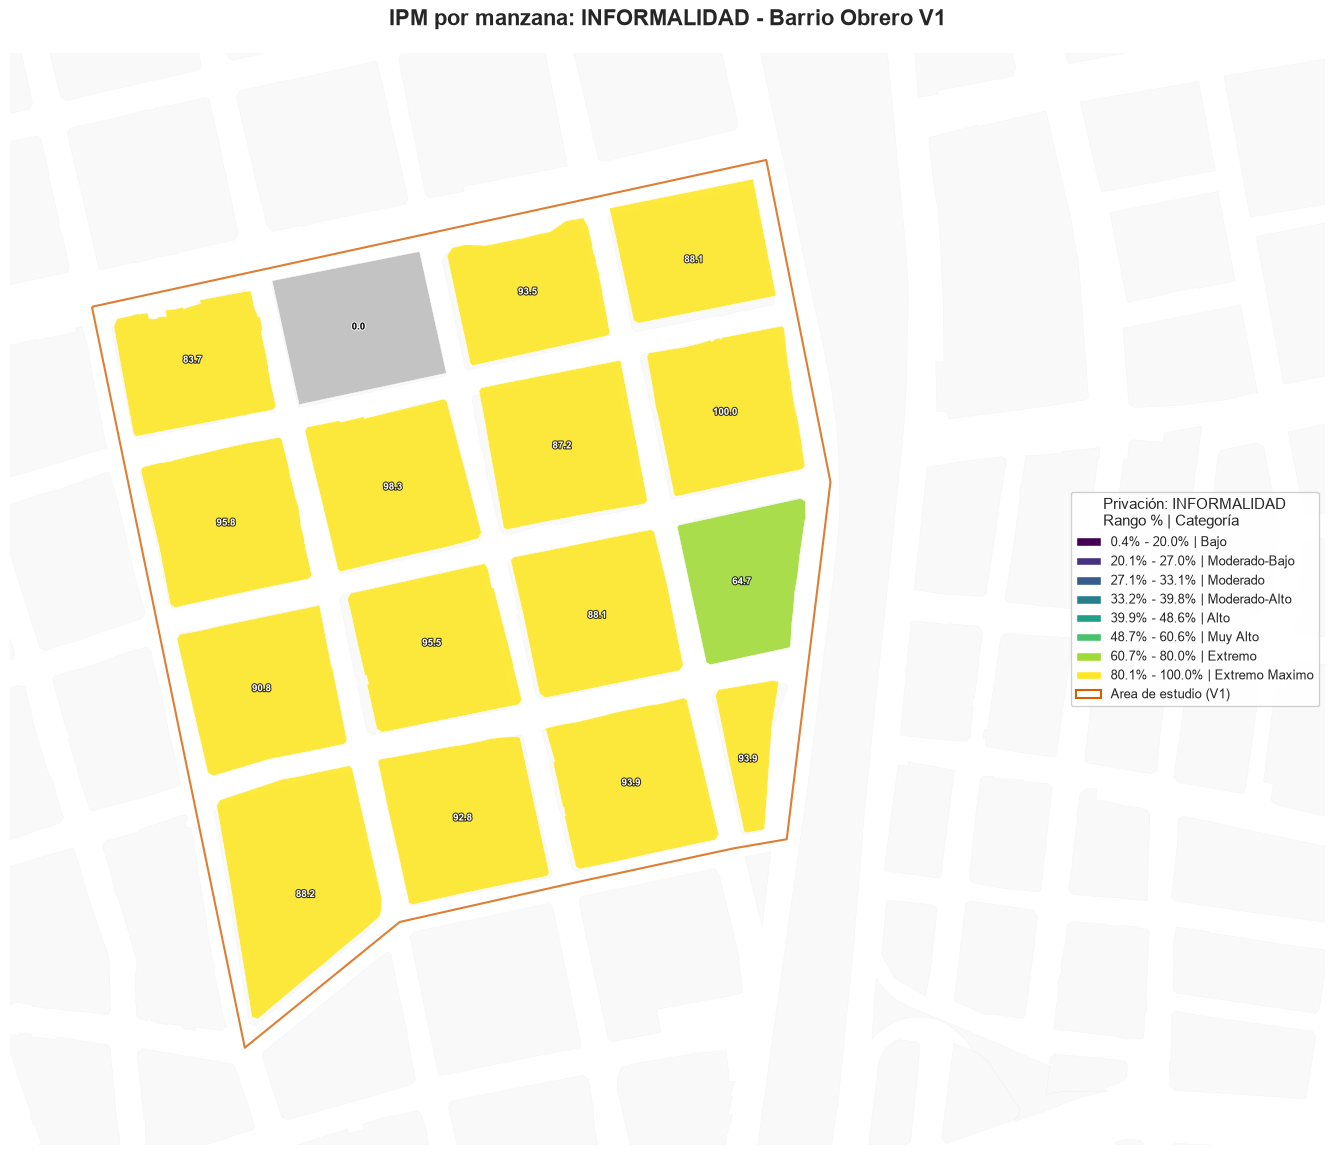

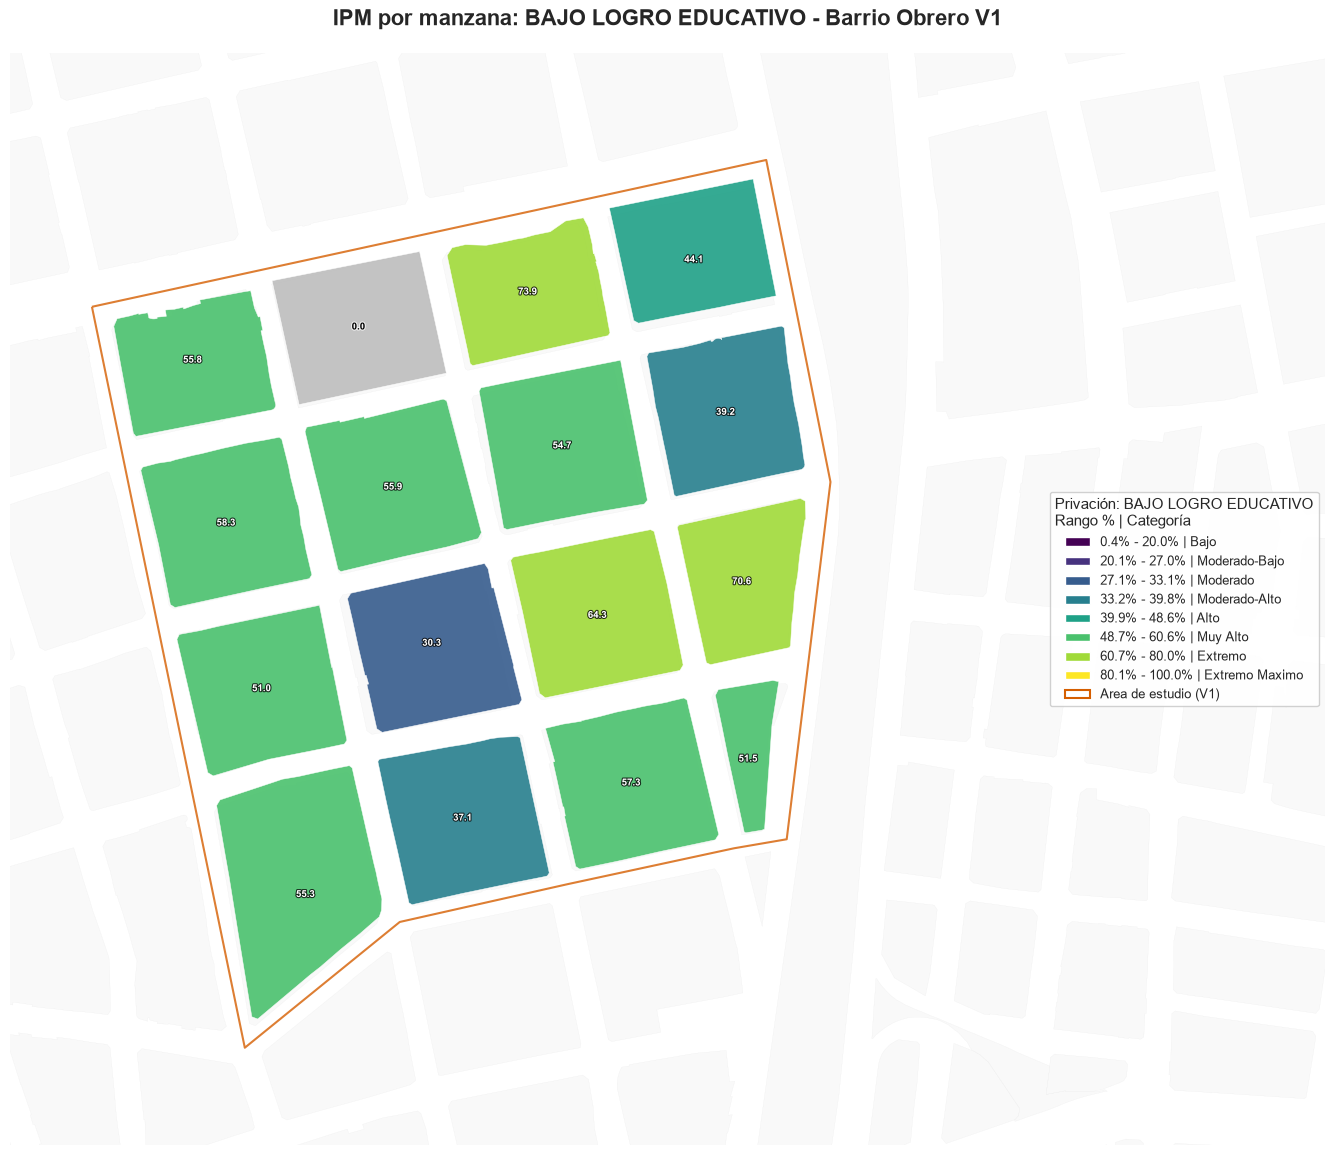

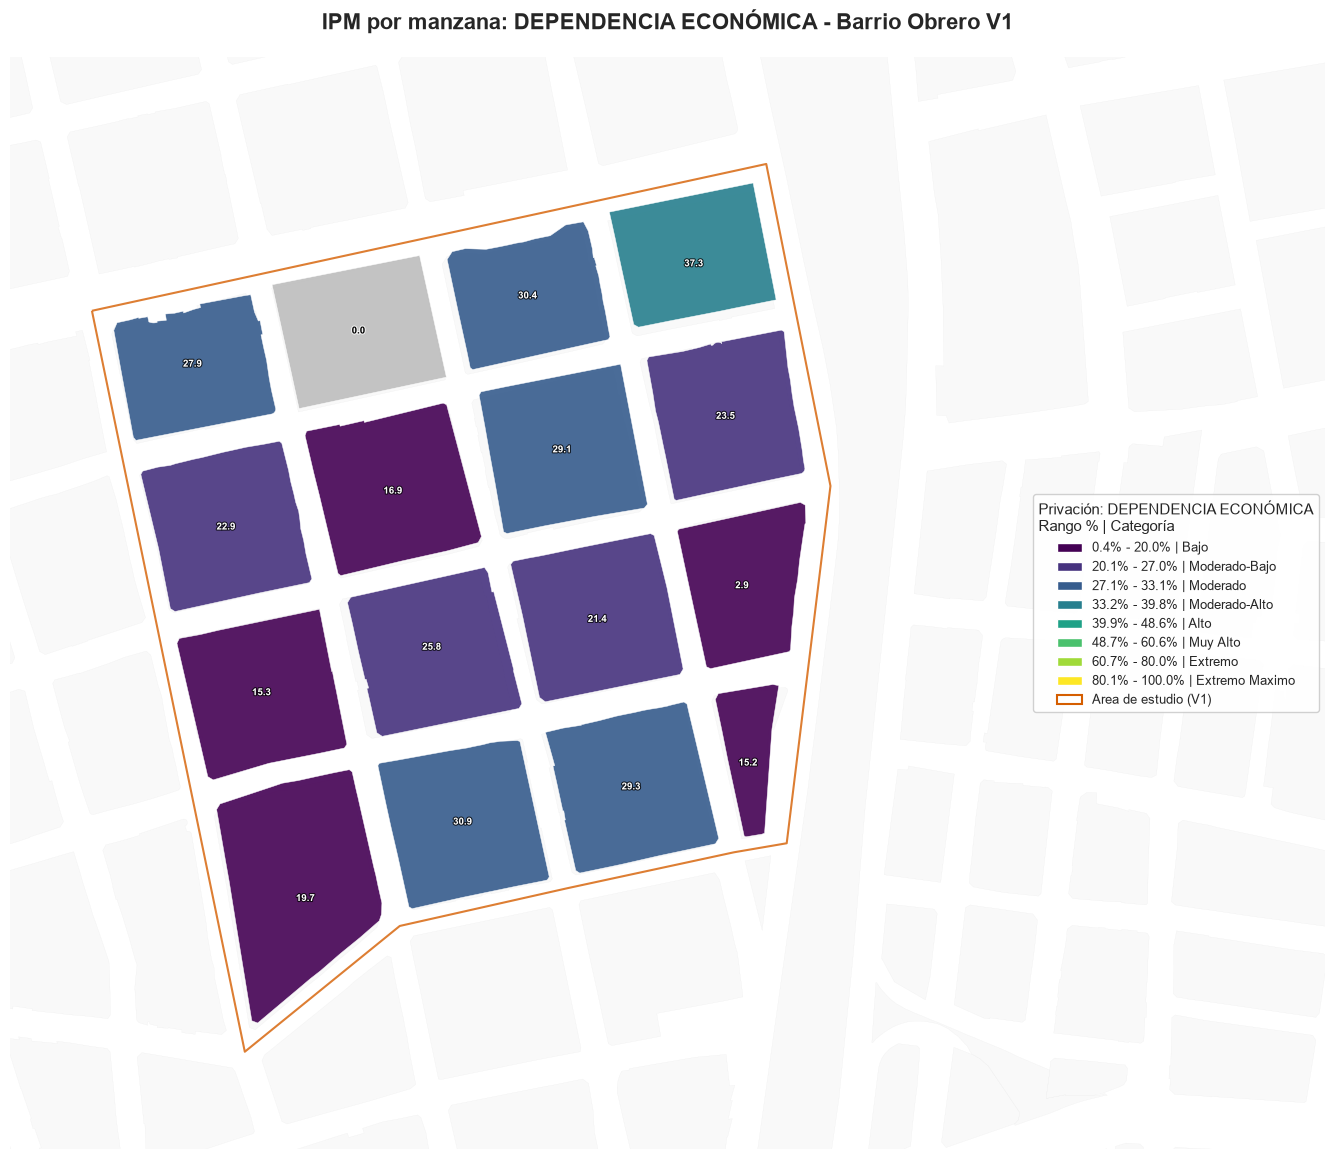

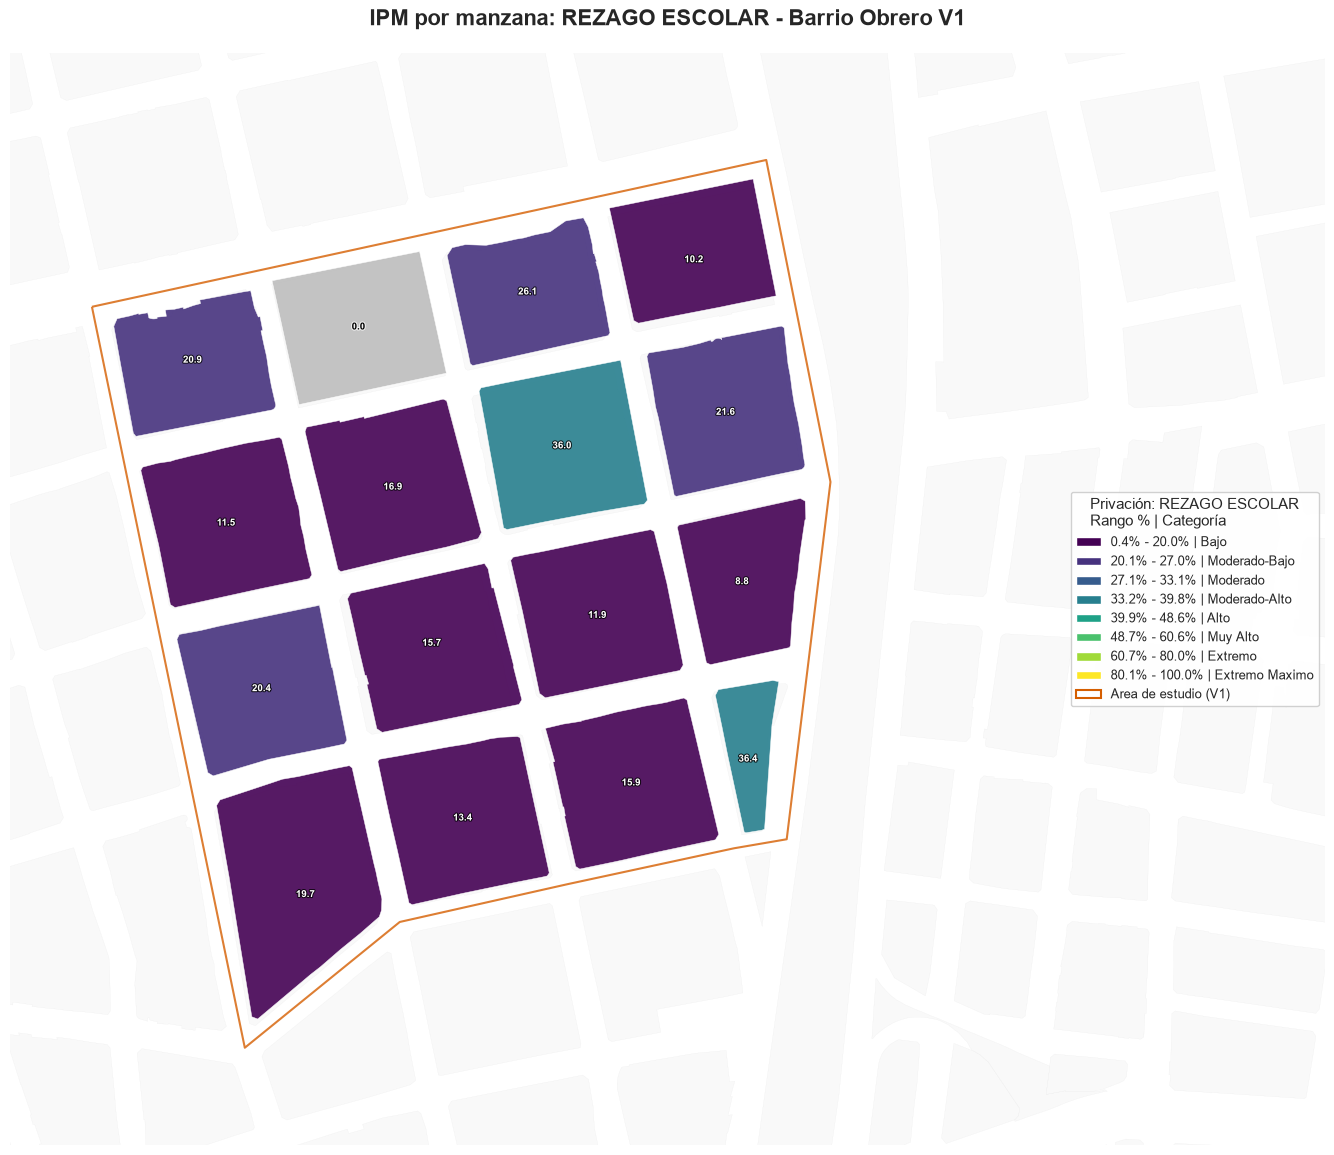

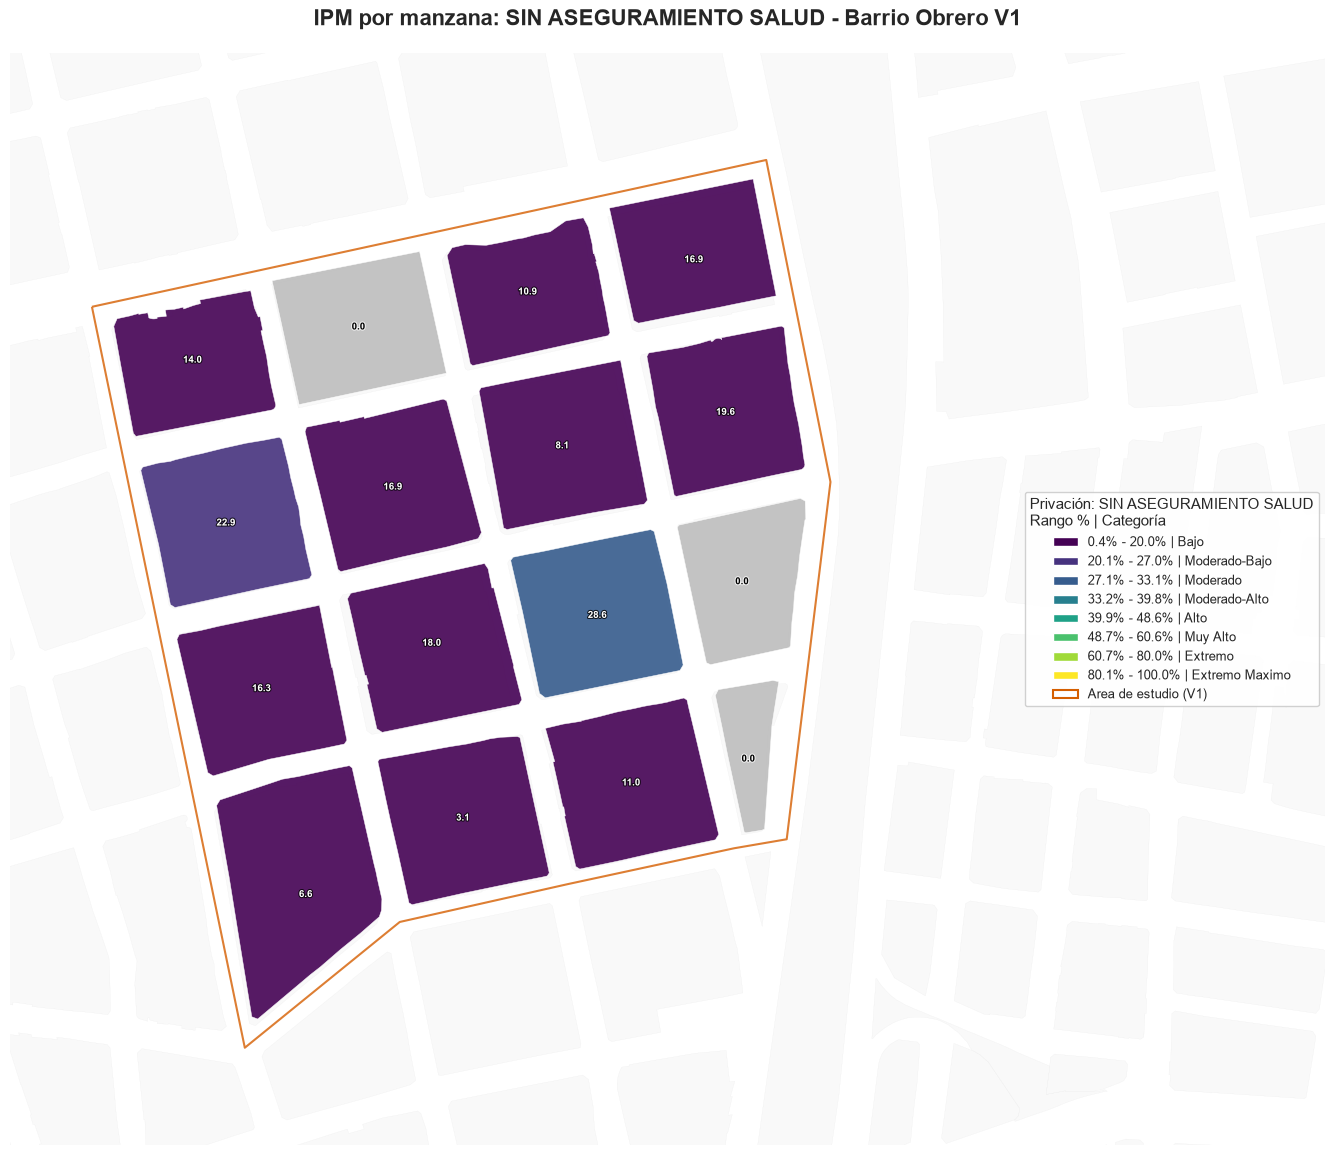

In [6]:
# 6. Generar los 5 mapas prioritarios
print('Generando mapas sincronizados con el Estándar Maestro del Notebook 01...')
for var in top_5:
    plot_ipm_variable_master(gdf, gdf_fondo, gdf_area, var, diccionario_nombres[var])

In [7]:
# 7. Consolidar IPM + ICS y exportar GeoJSON
# Cruce IPM <-> ICS por COD_MZN (deduplicando ICS que trae codigos repetidos)
ics_dedup = gdf_ics.groupby('COD_MZN', as_index=False)['ics'].mean()
gdf_exp = gdf.drop_duplicates('COD_MZN').merge(ics_dedup, on='COD_MZN', how='left')
print(f'IPM global promedio (V1): {gdf_exp["ipm"].mean():.2f} | ICS promedio: {gdf_exp["ics"].mean():.2f}')

# Carpeta de salida del usuario (Desktop) + fallback a outputs del repo
DEST_USER = r"C:\Users\Jorge\Desktop\mapa_Analitico_ciudad_Paraiso\data\Barrio_Obrero_geojson\IPM_BARRIO_OBRERO_2_POLIGONOS"
try:
    os.makedirs(DEST_USER, exist_ok=True)
    out_path = os.path.join(DEST_USER, 'IPM_Barrio_Obrero_V1.geojson')
    gdf_exp.to_crs('EPSG:4326').to_file(out_path, driver='GeoJSON')
    print(f'Exportado a: {out_path} ({len(gdf_exp)} manzanas)')
except Exception as e:
    # Si la ruta del Desktop no existe (p.ej. en Colab), exportar a outputs del repo
    fallback = os.path.join(BASE_DIR, 'indice_Pobreza/outputs/IPM_Barrio_Obrero_V1.geojson')
    os.makedirs(os.path.dirname(fallback), exist_ok=True)
    gdf_exp.to_crs('EPSG:4326').to_file(fallback, driver='GeoJSON')
    print(f'No se pudo escribir en Desktop ({e}). Exportado a: {fallback}')

# Descarga directa en Colab
if 'google.colab' in sys.modules:
    from google.colab import files
    tmp = 'IPM_Barrio_Obrero_V1.geojson'
    gdf_exp.to_crs('EPSG:4326').to_file(tmp, driver='GeoJSON')
    files.download(tmp)

IPM global promedio (V1): 9.06 | ICS promedio: 25.44
Exportado a: C:\Users\Jorge\Desktop\mapa_Analitico_ciudad_Paraiso\data\Barrio_Obrero_geojson\IPM_BARRIO_OBRERO_2_POLIGONOS\IPM_Barrio_Obrero_V1.geojson (16 manzanas)
